# 05 The Singing Bowl

**Series:** Physics of the Integratron (Landers, California)
**Topic T5:** how a singing bowl vibrates, why its tone wobbles, and how its notes line up with the dome's resonances.

Sound baths in the Integratron use singing bowls, including quartz crystal bowls. Notebooks 01 and 02 treated the sound source as a simple clap or note. This notebook looks at the bowl itself, then puts it back in the dome.

1. **Rim patterns.** The rim bends into 4, 6, 8 or more lobes, each pattern with its own frequency.
2. **Inharmonic overtones.** Those frequencies are not whole-number multiples of the lowest one.
3. **The warble.** Small imperfections split each note into two close frequencies, which beat.
4. **A struck bowl.** Adding the partials with their decay times gives the bowl's sound.
5. **The bowl in the dome.** Each partial lands on a peak or a dip of the dome's comb of resonances from notebook 02.

The bowl numbers below are typical values chosen for illustration: a fundamental of 220 Hz, a ring of decay times, and small splits. They are not measurements of any particular bowl.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import spectrogram
from IPython.display import Audio, display
from ipywidgets import interact, FloatSlider, IntSlider

SPEED_OF_SOUND = 343.0                   # m/s, air at 20 °C
DOME_RADIUS = 55 * 0.3048 / 2            # 55 ft diameter -> 8.38 m
R = DOME_RADIUS
ROUND_TRIP_S = 2 * R / SPEED_OF_SOUND

BOWL_FUNDAMENTAL_HZ = 220.0              # assumed, a typical mid-sized bowl
AUDIO_RATE = 22050                       # samples per second

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
SLIDER_STYLE = {"handle_color": BLUE}  # visible knob on white backgrounds
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "lines.linewidth": 2,
})


def ring_ratio(n):
    # Bending frequency of rim mode n for a thin ring, relative to n = 2
    shape = lambda k: k * (k ** 2 - 1) / np.sqrt(k ** 2 + 1)
    return shape(np.asarray(n, float)) / shape(2.0)


def play(samples):
    # Normalise and hand the samples to the notebook's audio player
    display(Audio(samples / np.max(np.abs(samples)), rate=AUDIO_RATE, normalize=False))


MODES = np.arange(2, 7)
for n in MODES:
    print(f"n = {n}: {ring_ratio(n):5.2f} x fundamental = "
          f"{BOWL_FUNDAMENTAL_HZ * ring_ratio(n):6.0f} Hz")

n = 2:  1.00 x fundamental =    220 Hz
n = 3:  2.83 x fundamental =    622 Hz
n = 4:  5.42 x fundamental =   1193 Hz
n = 5:  8.77 x fundamental =   1930 Hz
n = 6: 12.87 x fundamental =   2831 Hz


## 1. Rim patterns

Strike or rub a bowl and its rim bends out of round. Seen from above, the rim pushes out in some places and in at others. The simplest pattern has $n = 2$: the rim becomes an oval, then half a cycle later an oval turned by 90°.

For pattern $n$ the rim's outward movement around the bowl is

$$w(\phi, t) = A \cos(n\phi)\, \cos(2\pi f_n t)$$

- **Antinodes** are where the rim moves most: $2n$ points around the rim.
- **Nodes** are where it does not move at all: another $2n$ points, halfway between the antinodes.

The figure draws the rim from above with the bending exaggerated about 50 times. The two outlines are half a cycle apart.

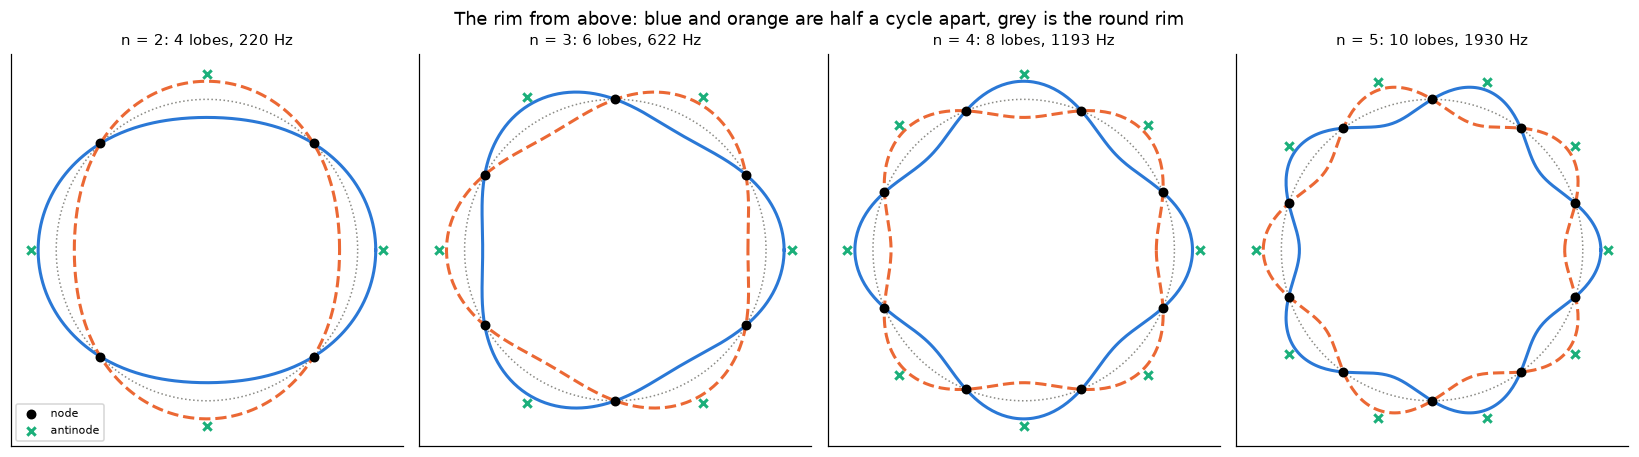

In [2]:
def draw_rim(ax, n, phase, colour, style="-", bend=0.12):
    phi = np.linspace(0, 2 * np.pi, 400)
    radius = 1 + bend * np.cos(n * phi) * np.cos(2 * np.pi * phase)
    ax.plot(radius * np.cos(phi), radius * np.sin(phi), color=colour, linestyle=style)


def mark_nodes(ax, n):
    nodes = (np.arange(2 * n) + 0.5) * np.pi / n
    antinodes = np.arange(2 * n) * np.pi / n
    ax.scatter(np.cos(nodes), np.sin(nodes), s=30, color="k", zorder=4, label="node")
    ax.scatter(1.17 * np.cos(antinodes), 1.17 * np.sin(antinodes), s=30, marker="x",
               color=AQUA, zorder=4, label="antinode")


fig, axes = plt.subplots(1, 4, figsize=(15, 4.2))
for ax, n in zip(axes, [2, 3, 4, 5]):
    circle = np.linspace(0, 2 * np.pi, 200)
    ax.plot(np.cos(circle), np.sin(circle), color=GREY, linewidth=1, linestyle=":")
    draw_rim(ax, n, 0.0, BLUE)
    draw_rim(ax, n, 0.5, ORANGE, "--")
    mark_nodes(ax, n)
    ax.set_aspect("equal")
    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-1.3, 1.3)
    ax.grid(False)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"n = {n}: {2 * n} lobes, {BOWL_FUNDAMENTAL_HZ * ring_ratio(n):.0f} Hz",
                 fontsize=10)
axes[0].legend(loc="lower left", fontsize=7)
fig.suptitle("The rim from above: blue and orange are half a cycle apart, grey is the round rim")
plt.tight_layout()
plt.show()

**What the figure shows**

Four rim patterns seen from above. The dotted grey circle is the rim at rest.

- **n = 2, 220 Hz:** the rim squeezes into an oval (blue), then half a cycle later into the same oval turned 90° (orange). The four black dots, at 45°, 135°, 225° and 315°, sit on the grey circle in both outlines. They are the nodes. The green crosses mark the four antinodes, where the rim swings furthest.
- **n = 3, 622 Hz:** a rounded triangle that flips to the opposite triangle. Six nodes, six antinodes.
- **n = 4, 1193 Hz** and **n = 5, 1930 Hz:** eight and ten lobes. The rim has to bend more sharply over a shorter length, which is why the frequency climbs so fast with $n$.

A light touch at an antinode damps that pattern. A touch at a node does not, because the rim is not moving there.

### Watch one pattern move

The slider steps through one cycle of a single pattern. The right plot unrolls the rim: angle around the bowl across, outward movement up.

In [3]:
@interact(
    n=IntSlider(value=2, min=2, max=6, description="pattern n", continuous_update=False,
                style=SLIDER_STYLE),
    phase=FloatSlider(value=0.0, min=0.0, max=1.0, step=0.05, description="cycle",
                      continuous_update=False, style=SLIDER_STYLE),
)
def show_rim_motion(n, phase):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4),
                                   gridspec_kw={"width_ratios": [1, 1.6]})
    circle = np.linspace(0, 2 * np.pi, 200)
    ax1.plot(np.cos(circle), np.sin(circle), color=GREY, linewidth=1, linestyle=":")
    draw_rim(ax1, n, phase, BLUE)
    mark_nodes(ax1, n)
    ax1.set_aspect("equal")
    ax1.set_xlim(-1.3, 1.3)
    ax1.set_ylim(-1.3, 1.3)
    ax1.grid(False)
    ax1.set_xticks([])
    ax1.set_yticks([])
    ax1.set_title(f"Rim from above, {phase:.2f} of a cycle", fontsize=10)

    phi = np.linspace(0, 360, 721)
    ax2.plot(phi, np.cos(n * np.radians(phi)), color=GREY, linewidth=1, linestyle=":",
             label="largest movement")
    ax2.plot(phi, np.cos(n * np.radians(phi)) * np.cos(2 * np.pi * phase), color=BLUE,
             label="rim now")
    nodes = (np.arange(2 * n) + 0.5) * 180 / n
    ax2.scatter(nodes, np.zeros_like(nodes), s=30, color="k", zorder=4, label="nodes")
    ax2.set_xlim(0, 360)
    ax2.set_xticks(np.arange(0, 361, 45))
    ax2.set_ylim(-1.15, 1.15)
    ax2.set_xlabel("angle around the rim (degrees)")
    ax2.set_ylabel("outward movement")
    ax2.legend(fontsize=8, loc="upper right")
    ax2.set_title(f"Pattern n = {n}, {BOWL_FUNDAMENTAL_HZ * ring_ratio(n):.0f} Hz", fontsize=10)
    plt.tight_layout()
    plt.show()

interactive(children=(IntSlider(value=2, continuous_update=False, description='pattern n', max=6, min=2, style…

**What the plots show** (default n = 2, start of the cycle)

- **Left:** the rim at the chosen moment, with the nodes (black) and antinodes (green).
- **Right:** the same rim unrolled. The dotted grey curve is the largest movement each point ever reaches. The blue curve is where the rim is now. The black dots are the nodes, where both curves cross zero.

**Try this:**

- Step the cycle from 0 to 0.5. The blue curve shrinks to a flat line at 0.25 and comes back upside down at 0.5. At 0.25 the rim is momentarily round and moving at its fastest.
- Set n = 3 and cycle 0.25. The rim is a perfect circle and the blue line lies flat on zero, with six nodes at 30°, 90°, 150°, 210°, 270° and 330°.
- Step through n = 2 to 6. The nodes are always evenly spaced, $180°/n$ apart.

## 2. Inharmonic overtones

A string or a voice has overtones at whole-number multiples of its lowest note: 2×, 3×, 4×. The ear hears them as one pitch with a tone colour.

A bowl's rim behaves like a bending ring. For a thin ring the frequency of pattern $n$ is

$$f_n \propto \frac{n\,(n^2 - 1)}{\sqrt{n^2 + 1}}$$

Relative to $n = 2$ this gives 1, 2.83, 5.42, 8.77, 12.87. These are not whole numbers, so the overtones are **inharmonic**. That is the main reason a bowl sounds like a shimmering cluster instead of a single pitched note.

A real bowl is not a thin ring. Its wall is thicker near the base and it has a bottom, so measured ratios differ a little from the ring formula. The pattern stays the same: overtones that spread further apart than a harmonic series.

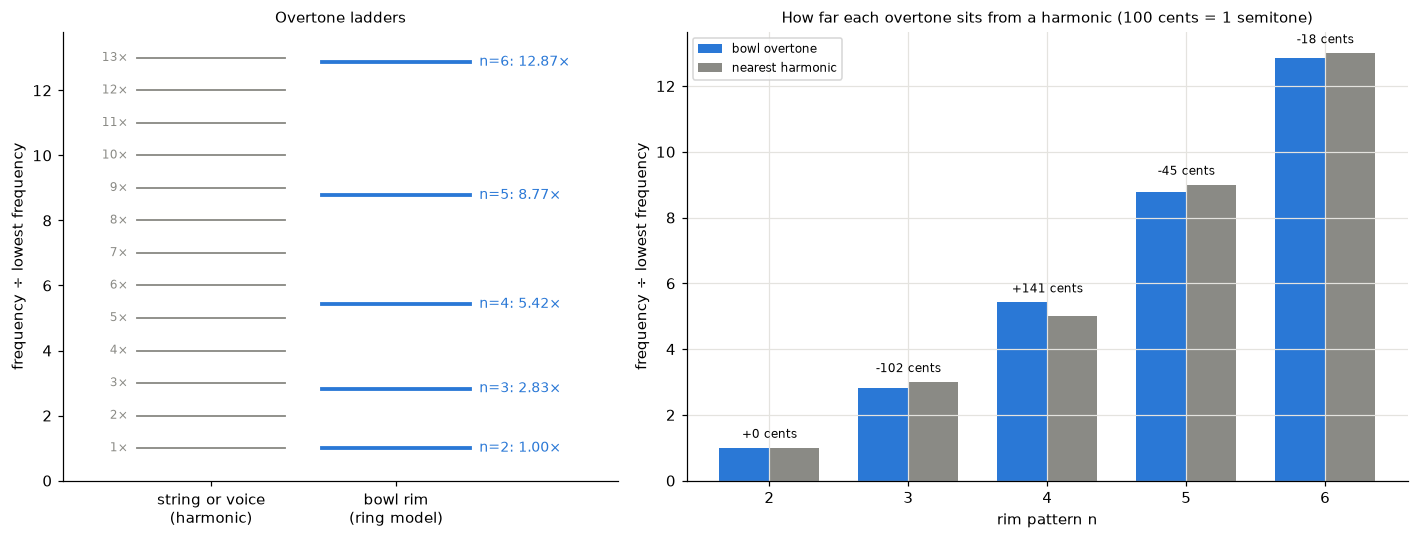

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5),
                               gridspec_kw={"width_ratios": [1, 1.3]})
ratios = ring_ratio(MODES)
harmonics = np.arange(1, 14)
for h in harmonics:
    ax1.plot([0.1, 0.9], [h, h], color=GREY, linewidth=1.2)
    ax1.text(0.05, h, f"{h}×", ha="right", va="center", color=GREY, fontsize=8)
for n, ratio in zip(MODES, ratios):
    ax1.plot([1.1, 1.9], [ratio, ratio], color=BLUE, linewidth=2.5)
    ax1.text(1.95, ratio, f"n={n}: {ratio:.2f}×", va="center", color=BLUE, fontsize=9)
ax1.set_xlim(-0.3, 2.7)
ax1.set_ylim(0, 13.8)
ax1.set_xticks([0.5, 1.5])
ax1.set_xticklabels(["string or voice\n(harmonic)", "bowl rim\n(ring model)"])
ax1.set_ylabel("frequency ÷ lowest frequency")
ax1.set_title("Overtone ladders", fontsize=10)
ax1.grid(False)

nearest = np.round(ratios)
ax2.bar(MODES - 0.18, ratios, width=0.36, color=BLUE, label="bowl overtone")
ax2.bar(MODES + 0.18, nearest, width=0.36, color=GREY, label="nearest harmonic")
for n, ratio, near in zip(MODES, ratios, nearest):
    cents = 1200 * np.log2(ratio / near)
    ax2.text(n, max(ratio, near) + 0.3, f"{cents:+.0f} cents", ha="center", fontsize=8)
ax2.set_xticks(MODES)
ax2.set_xlabel("rim pattern n")
ax2.set_ylabel("frequency ÷ lowest frequency")
ax2.set_title("How far each overtone sits from a harmonic (100 cents = 1 semitone)",
              fontsize=10)
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

**What the plots show**

- **Left:** two ladders of overtones, each relative to its lowest note. The grey ladder is a harmonic series, with a rung at every whole number. The blue ladder is the bowl. It skips most of the rungs. Its second note is at 2.83×, which is exactly $2\sqrt{2}$, one and a half octaves above the fundamental. The rungs then spread further apart: 5.42×, 8.77×, 12.87×.
- **Right:** each bowl overtone next to the nearest whole number, with the gap in cents (100 cents is one semitone). The n = 3 overtone is 102 cents flat of 3×, about a semitone. The n = 4 overtone is 141 cents sharp of 5×. The n = 5 and n = 6 overtones are 45 and 18 cents flat of 9× and 13×.

Gaps of a semitone or more are easy to hear. The overtones do not fuse into one pitch the way a voice's do, so the bowl sounds like a chord of unrelated tones.

## 3. The warble

A perfect round bowl has two copies of every pattern: one with antinodes at 0°, and one turned by half a lobe so its antinodes sit on the first one's nodes. In a perfectly even bowl the two have the same frequency. This is the same kind of sharing as the dome's modes in notebook 02, where every mode with the same $l$ and $n$ had one frequency.

Real bowls are never perfectly even. Small differences in thickness or shape give the two copies slightly different frequencies, $f$ and $f + \Delta$. Both ring at once. Added together, they drift in and out of step $\Delta$ times per second, so the loudness rises and falls:

$$\cos(2\pi f t) + b\cos\big(2\pi (f+\Delta) t\big) \quad\Rightarrow\quad \text{envelope} = \sqrt{1 + b^2 + 2b\cos(2\pi \Delta t)}$$

This is called **beating**, and it gives a bowl its slow pulse. The sliders set the split $\Delta$ and the strength $b$ of the second copy. The player below the plot lets you hear it.

In [5]:
@interact(
    split_hz=FloatSlider(value=1.0, min=0.0, max=6.0, step=0.1, description="split Δ (Hz)",
                         continuous_update=False, style=SLIDER_STYLE),
    second=FloatSlider(value=1.0, min=0.0, max=1.0, step=0.05, description="strength b",
                       continuous_update=False, style=SLIDER_STYLE),
)
def show_warble(split_hz, second):
    f = BOWL_FUNDAMENTAL_HZ
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4.3),
                                        gridspec_kw={"width_ratios": [0.8, 1.6, 1]})
    circle = np.linspace(0, 2 * np.pi, 200)
    ax1.plot(np.cos(circle), np.sin(circle), color=GREY, linewidth=1, linestyle=":")
    phi = np.linspace(0, 2 * np.pi, 400)
    for turn, colour, label in [(0, BLUE, f"{f:.1f} Hz"),
                                (np.pi / 4, ORANGE, f"{f + split_hz:.1f} Hz")]:
        radius = 1 + 0.12 * np.cos(2 * (phi - turn))
        ax1.plot(radius * np.cos(phi), radius * np.sin(phi), color=colour, label=label)
    ax1.set_aspect("equal")
    ax1.set_xlim(-1.3, 1.3)
    ax1.set_ylim(-1.3, 1.3)
    ax1.grid(False)
    ax1.set_xticks([])
    ax1.set_yticks([])
    ax1.legend(fontsize=8, loc="lower left")
    ax1.set_title("The two copies of n = 2,\nturned 45° apart", fontsize=10)

    t = np.arange(0, 4.0, 1 / AUDIO_RATE)
    signal = np.cos(2 * np.pi * f * t) + second * np.cos(2 * np.pi * (f + split_hz) * t)
    envelope = np.sqrt(1 + second ** 2 + 2 * second * np.cos(2 * np.pi * split_hz * t))
    ax2.plot(t, signal, color=BLUE, linewidth=0.3)
    ax2.plot(t, envelope, color=ORANGE, linewidth=1.5, label="loudness envelope")
    ax2.plot(t, -envelope, color=ORANGE, linewidth=1.5)
    ax2.set_xlim(0, 4)
    ax2.set_ylim(-2.2, 2.6)
    ax2.set_xlabel("time (s)")
    ax2.set_ylabel("sound pressure")
    ax2.legend(fontsize=8, loc="upper right")
    beat = f"one beat every {1 / split_hz:.2f} s" if split_hz > 0 else "no beats"
    ax2.set_title(f"The sum: {beat}", fontsize=10)

    window = np.hanning(len(t))
    spectrum = np.abs(np.fft.rfft(signal * window)) ** 2
    freqs = np.fft.rfftfreq(len(t), 1 / AUDIO_RATE)
    zoom = np.abs(freqs - f - split_hz / 2) < 8
    ax3.plot(freqs[zoom], 10 * np.log10(spectrum[zoom] / spectrum.max() + 1e-12),
             color=BLUE)
    ax3.set_ylim(-60, 3)
    ax3.set_xlabel("frequency (Hz)")
    ax3.set_ylabel("power (dB)")
    ax3.set_title("Spectrum: two lines Δ apart", fontsize=10)
    plt.tight_layout()
    plt.show()

    fade = np.minimum(1, np.minimum(t, t[-1] - t) / 0.05)
    play(signal * fade)

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='split Δ (Hz)', max=6.0, sty…

**What the plots show** (defaults: split 1.0 Hz, both copies equally strong)

- **Left:** the two copies of the n = 2 pattern, turned 45° apart. Blue rings at 220.0 Hz, orange at 221.0 Hz.
- **Middle:** their sum over 4 s. The individual cycles are too fast to see and merge into a solid blue band. The orange envelope swells to 2 and falls to 0 once every second. At 0.5 s, 1.5 s, 2.5 s and 3.5 s the two copies are exactly out of step and cancel to silence.
- **Right:** the spectrum shows two separate lines, at 220 Hz and 221 Hz. The beat is not a third frequency. It is the two lines drifting in and out of step.

The player below the plots plays the 4 s sum.

**Try this:**

- Set the split to 3 Hz and the strength to 0.4. The beat is three times faster, one every 0.33 s. The envelope now only swings between 0.6 and 1.4, so it never falls silent. The second spectral line is 8 dB lower.
- Set the split to 0. The lines merge into one and the envelope is flat. A perfect bowl would not warble.

The strength $b$ also depends on where you are. Each copy sends out most sound in the direction of its own antinodes. Directly in line with a blue antinode you sit on an orange node and hear mostly blue, so the beat is shallow. Halfway between, at 22.5°, both are equal and the beat is deepest. Walking around a bowl changes how strongly it pulses.

## 4. A struck bowl

Now put the pieces together. A strike excites several rim patterns at once. Each pattern

- rings at its own frequency from the ring formula,
- is split into a close pair that beats,
- dies away at its own rate.

Higher patterns die faster. A common simple model gives every pattern the same number of cycles before it fades, so the decay time scales as $1/f$. The fundamental's decay time and the split sizes below are assumed.

The slider sets the fundamental's decay time $T_{60}$. The plots show the sound's waveform and its **spectrogram**: time across, frequency up, colour for loudness.

In [6]:
STRIKE_AMPLITUDES = np.array([1.0, 0.6, 0.35, 0.2, 0.1])   # assumed, n = 2 to 6
STRIKE_SPLITS_HZ = np.array([0.8, 1.7, 2.6, 3.5, 4.4])      # assumed beat rates


def struck_bowl(fundamental_hz, t60_s, duration_s=8.0):
    t = np.arange(0, duration_s, 1 / AUDIO_RATE)
    sound = np.zeros_like(t)
    for n, amp, split in zip(MODES, STRIKE_AMPLITUDES, STRIKE_SPLITS_HZ):
        f = fundamental_hz * ring_ratio(n)
        decay = t60_s * fundamental_hz / f          # same number of cycles for each
        envelope = amp * 10 ** (-3 * t / decay)      # -60 dB after `decay` seconds
        sound += envelope * (np.cos(2 * np.pi * f * t)
                             + 0.8 * np.cos(2 * np.pi * (f + split) * t))
    attack = np.minimum(1, t / 0.003)
    return t, sound * attack


@interact(
    t60_s=FloatSlider(value=20.0, min=2.0, max=40.0, step=1.0,
                      description="T60 fund. (s)", continuous_update=False,
                      style=SLIDER_STYLE),
)
def show_strike(t60_s):
    t, sound = struck_bowl(BOWL_FUNDAMENTAL_HZ, t60_s)
    freqs, times, power = spectrogram(sound, fs=AUDIO_RATE, nperseg=8192,
                                      noverlap=7168)
    power_db = 10 * np.log10(power / power.max() + 1e-12)

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7.5),
                                   gridspec_kw={"height_ratios": [1, 2]}, sharex=True)
    ax1.plot(t, sound / np.abs(sound).max(), color=BLUE, linewidth=0.3)
    ax1.set_ylabel("sound pressure")
    ax1.set_title(f"Struck bowl, fundamental {BOWL_FUNDAMENTAL_HZ:.0f} Hz, "
                  f"fundamental T60 = {t60_s:.0f} s", fontsize=10)

    image = ax2.pcolormesh(times, freqs, power_db, cmap="magma", vmin=-70, vmax=0,
                           shading="auto")
    for n in MODES:
        f = BOWL_FUNDAMENTAL_HZ * ring_ratio(n)
        ax2.text(t[-1] * 1.005, f, f" n={n}", va="center", fontsize=8, color=BLUE)
    ax2.set_ylim(0, 3200)
    ax2.set_xlim(0, t[-1])
    ax2.set_xlabel("time (s)")
    ax2.set_ylabel("frequency (Hz)")
    ax2.grid(False)
    fig.colorbar(image, ax=ax2, label="dB", pad=0.06)
    plt.tight_layout()
    plt.show()

    play(sound)

interactive(children=(FloatSlider(value=20.0, continuous_update=False, description='T60 fund. (s)', max=40.0, …

**What the plots show** (default: fundamental rings for 20 s)

- **Top:** the waveform over 8 s. A sharp strike, a quick fall in the first second as the high partials die, then a slow fade. The loudness pulses with dips roughly every 1.25 s. That is the 0.8 Hz beat of the fundamental's split pair.
- **Bottom:** the spectrogram. Five bright lines at 220, 622, 1193, 1930 and 2831 Hz, the partials from section 2. They fade from the top down. On this colour scale n = 6 is gone after about 1 s, n = 5 after about 2 s, n = 4 after 3.5 s and n = 3 after 5.5 s. The fundamental is still bright at 8 s.

The model gives decay times of 20, 7.1, 3.7, 2.3 and 1.6 s for n = 2 to 6. Within two seconds the strike has turned into an almost pure 220 Hz tone with a slow pulse. The player plays the 8 s sound.

**Try this:**

- Set the fundamental's $T_{60}$ to 5 s. All decay times shrink by a factor of four. The high partials vanish within half a second and the whole sound is gone before 5 s.

## 5. The bowl in the dome

Notebook 02 found that a note played at the centre of the dome is reinforced or suppressed depending on its exact frequency. The echoes return every $2R/c = 49$ ms. Notes on a comb of peaks every $c/2R = 20.5$ Hz build up strongly, and notes between the peaks are slightly weakened:

$$|H(f)|^2 = \left|\frac{1}{1 + r\, e^{\,i\,2\pi f \cdot 2R/c}}\right|^2, \qquad r = \sqrt{1 - \alpha}$$

This holds for a bowl and a listener both at the centre. Each of the bowl's partials sits somewhere on this comb. The plots show where.

- **Top row:** the comb around each partial, ±25 Hz. The blue line is the partial, the orange dashed line is its split partner from section 4. The dot shows the dome's gain at the partial.
- **Bottom:** the gain for every partial and its partner.

The sliders set the wall absorption α and the bowl's exact fundamental. Move the fundamental in small steps to see the partials slide across the comb.

In [7]:
def centre_gain_db(f, alpha):
    r = np.sqrt(1 - alpha)
    return 10 * np.log10(np.abs(1 / (1 + r * np.exp(2j * np.pi * f * ROUND_TRIP_S))) ** 2)


@interact(
    alpha=FloatSlider(value=0.05, min=0.01, max=0.5, step=0.01, description="wall α",
                      continuous_update=False, style=SLIDER_STYLE),
    fundamental_hz=FloatSlider(value=220.0, min=210.0, max=230.0, step=0.05,
                               description="fund. (Hz)", readout_format=".2f",
                               continuous_update=False, style=SLIDER_STYLE),
)
def show_bowl_in_dome(alpha, fundamental_hz):
    partials = fundamental_hz * ring_ratio(MODES)
    partners = partials + STRIKE_SPLITS_HZ

    fig = plt.figure(figsize=(15, 7))
    grid = fig.add_gridspec(2, len(MODES), height_ratios=[1, 1.1])
    for col, (n, f, f2) in enumerate(zip(MODES, partials, partners)):
        ax = fig.add_subplot(grid[0, col])
        freq = np.linspace(f - 25, f + 25, 4000)
        ax.plot(freq, centre_gain_db(freq, alpha), color=GREY, linewidth=1)
        ax.axvline(f, color=BLUE, linewidth=1.5)
        ax.axvline(f2, color=ORANGE, linewidth=1.2, linestyle="--")
        gain = centre_gain_db(f, alpha)
        ax.scatter([f], [gain], s=50, color=BLUE, zorder=4)
        ax.set_ylim(-8, 34)
        ax.set_title(f"n={n}: {f:.1f} Hz, {gain:+.1f} dB", fontsize=9)
        ax.set_xlabel("Hz", fontsize=8)
        ax.tick_params(labelsize=7)
        if col == 0:
            ax.set_ylabel("dome gain at centre (dB)")

    ax = fig.add_subplot(grid[1, :])
    ax.bar(MODES - 0.18, centre_gain_db(partials, alpha), width=0.36, color=BLUE,
           label="partial")
    ax.bar(MODES + 0.18, centre_gain_db(partners, alpha), width=0.36, color=ORANGE,
           label="split partner")
    peak = centre_gain_db(0.5 / ROUND_TRIP_S, alpha)
    dip = centre_gain_db(1 / ROUND_TRIP_S, alpha)
    ax.axhline(peak, color=GREY, linestyle="--", linewidth=1)
    ax.axhline(dip, color=GREY, linestyle=":", linewidth=1)
    ax.text(6.55, peak, f" comb peak {peak:+.0f} dB", va="center", fontsize=8, color=GREY)
    ax.text(6.55, dip, f" comb dip {dip:+.0f} dB", va="center", fontsize=8, color=GREY)
    ax.set_xticks(MODES)
    ax.set_xticklabels([f"n={n}" for n in MODES])
    ax.set_xlim(1.5, 7.3)
    ax.set_ylabel("dome gain (dB)")
    ax.legend(fontsize=8, loc="upper left")
    ax.set_title(f"Gain for each partial, fundamental {fundamental_hz:.2f} Hz, α = {alpha:.2f}",
                 fontsize=10)
    plt.tight_layout()
    plt.show()

interactive(children=(FloatSlider(value=0.05, continuous_update=False, description='wall α', max=0.5, min=0.01…

**What the plots show** (defaults: α = 0.05, fundamental 220.00 Hz)

- **Top row:** every partial lands somewhere different on the comb. The fundamental at 220.0 Hz sits near a dip at −3.0 dB. The n = 3 partial at 622.3 Hz is on the rising slope of a peak at +5.4 dB. n = 4, 5 and 6 sit near dips, between −1.1 and +0.6 dB.
- **Bottom:** the split partners (orange) fare very differently from their partials (blue). The n = 3 partner at 624.0 Hz lands almost on a peak at +28.5 dB, 23 dB above its partial. The n = 5 partner gets +16.4 dB. The grey dashed and dotted lines are the comb's highest and lowest possible gain, +32 dB and −6 dB.

When one member of a split pair is 23 dB louder than the other, the weaker one is only 7% as strong. The beat from section 3 nearly disappears. At the centre of the dome, some partials lose their warble and others keep it.

These are steady-state gains. A peak needs the echo train to build up over many round trips, which takes seconds. A partial that dies in 1.6 s, like n = 6, never reaches the full peak gain. The comb also applies only to a bowl and a listener both at the centre.

**Try this:**

- Set the fundamental to 220.50 Hz. Everything reshuffles. Now n = 3 and n = 5 get about +18 dB, n = 4 gets +9.5 dB, and the n = 3 partner falls to +8.0 dB. Half a hertz changes which notes the dome favours.
- Set α to 0.3. The comb flattens to between −5 and +16 dB, and the differences between partials shrink.

### Sliding the bowl's pitch

The plot below steps the fundamental from 210 Hz to 230 Hz in very fine steps and tracks the dome's gain for each partial. The wall absorption is 0.05.

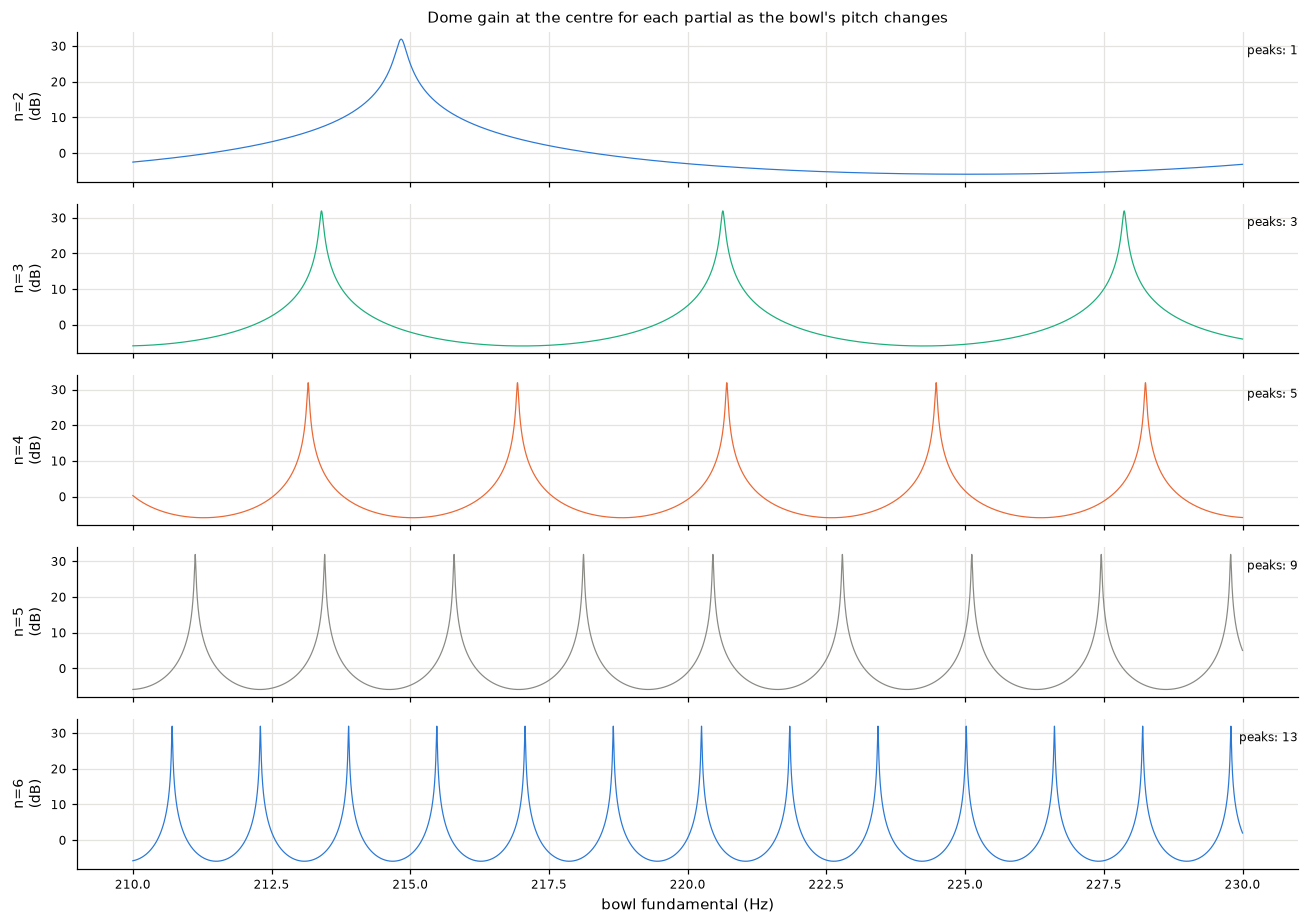

In [8]:
fundamentals = np.linspace(210.0, 230.0, 80001)
fig, axes = plt.subplots(len(MODES), 1, figsize=(12, 8.5), sharex=True)
for ax, n, colour in zip(axes, MODES, [BLUE, AQUA, ORANGE, GREY, BLUE]):
    gain = centre_gain_db(fundamentals * ring_ratio(n), 0.05)
    ax.plot(fundamentals, gain, color=colour, linewidth=0.8)
    peaks = np.sum((gain[1:-1] > gain[:-2]) & (gain[1:-1] > gain[2:]) & (gain[1:-1] > 20))
    ax.set_ylim(-8, 34)
    ax.set_ylabel(f"n={n}\n(dB)", fontsize=9)
    ax.text(1.0, 0.85, f"peaks: {peaks}", transform=ax.transAxes, ha="right", fontsize=8)
    ax.tick_params(labelsize=8)
axes[-1].set_xlabel("bowl fundamental (Hz)")
axes[0].set_title("Dome gain at the centre for each partial as the bowl's pitch changes",
                  fontsize=10)
plt.tight_layout()
plt.show()

**What the plot shows**

Each row is one partial. Across the plot the bowl's fundamental rises from 210 Hz to 230 Hz. Each spike is a bowl pitch at which that partial lands on a comb peak.

- **n = 2:** one peak, at a fundamental of 215.0 Hz. The fundamental only moves 20 Hz, about one comb period.
- **n = 3:** three peaks, 7.2 Hz apart.
- **n = 4:** five peaks, 3.8 Hz apart.
- **n = 5:** nine peaks, 2.3 Hz apart.
- **n = 6:** thirteen peaks, 1.6 Hz apart.

The spacing is $20.5\ \text{Hz} / (f_n / f_2)$. Each partial moves $f_n/f_2$ times as far as the fundamental, so the higher partials sweep across the comb much faster. A change of 1 Hz in the bowl's pitch moves n = 6 by 12.9 Hz, more than half a comb period. The spikes are also very narrow. For n = 6 a peak is only about 0.01 Hz wide in bowl pitch, so landing exactly on one is a matter of luck.

## Summary

| Idea | Formula | Bowl scale (assumed 220 Hz bowl) |
|---|---|---|
| Rim pattern | $w = A\cos(n\phi)\cos(2\pi f_n t)$ | $2n$ antinodes and $2n$ nodes |
| Overtone ratios (thin ring) | $n(n^2-1)/\sqrt{n^2+1}$, relative to $n = 2$ | 1, 2.83, 5.42, 8.77, 12.87 (220, 622, 1193, 1930, 2831 Hz) |
| Beat rate | split $\Delta$ | 0.8 Hz split: a pulse every 1.25 s |
| Partial decay | $T_{60} \propto 1/f$ | 20 s at 220 Hz, 1.6 s at 2831 Hz |
| Dome comb at the centre | peaks every $c/2R$ | 20.5 Hz apart, −6 to +32 dB at α = 0.05 |
| Bowl pitch between comb peaks | $20.5\ \text{Hz} \,/\, (f_n/f_2)$ | 20.5 Hz for n = 2, 1.6 Hz for n = 6 |

1. A bowl's rim bends into patterns with $2n$ lobes. Each pattern has its own frequency, with fixed nodes between the lobes.
2. The frequencies follow the ring formula, 1 : 2.83 : 5.42 : 8.77 : 12.87. They are not whole-number multiples, so the bowl sounds like a cluster of tones rather than one pitch.
3. Every pattern has two copies. Small imperfections split them by about a hertz and they beat. How deep the beat is depends on where you stand around the bowl.
4. Higher partials die first, so a struck bowl settles within a couple of seconds into its fundamental with a slow pulse.
5. At the dome's centre each partial gets anywhere from −6 to +32 dB, depending on exactly where it lands on the comb. The two members of a split pair can land very differently, which can remove the beat. A small change in the bowl's pitch reshuffles all of it.

**Next:** [06 Listening to the Dome](06_listening_to_the_dome.ipynb): play a clap, a voice and a bowl through the dome and hear the focusing and ringing together.